In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df=pd.read_csv(r'c:\Users\www\OneDrive\Desktop\ML Projects\Diabetes.patients\diabetes_patients_10000_full.csv')
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [3]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Sugar_Level', 'Creatinine', 'BMI',
       'Urea', 'Cholesterol', 'HbA1c', 'Class'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   str    
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  str    
dtypes: float64(7), int64(1), str(2)
memory usage: 781.4 KB


In [5]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [6]:
df.isna().sum()

Patient_ID            0
Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
HbA1c                 0
Class                 0
dtype: int64

In [7]:
from sklearn.impute import SimpleImputer
simple_impute=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
df[['Gender']]=simple_impute.fit_transform(df[['Gender']])

In [8]:
df['Cholesterol'].skew()

np.float64(-0.0018723224526564731)

In [9]:
from sklearn.impute import SimpleImputer
simple_impute=SimpleImputer(missing_values=np.nan,strategy='mean')
for col in['Age','Cholesterol','Urea','BMI','Creatinine','Blood_Sugar_Level']:
   df[col]=simple_impute.fit_transform(df[[col]])

In [10]:
df.isnull().sum()

Patient_ID           0
Age                  0
Gender               0
Blood_Sugar_Level    0
Creatinine           0
BMI                  0
Urea                 0
Cholesterol          0
HbA1c                0
Class                0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.set_index('Patient_ID', inplace=True)
display(df.head())

,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
Patient_ID,,,,,,,,,
1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


<Axes: xlabel='Blood_Sugar_Level', ylabel='Class'>

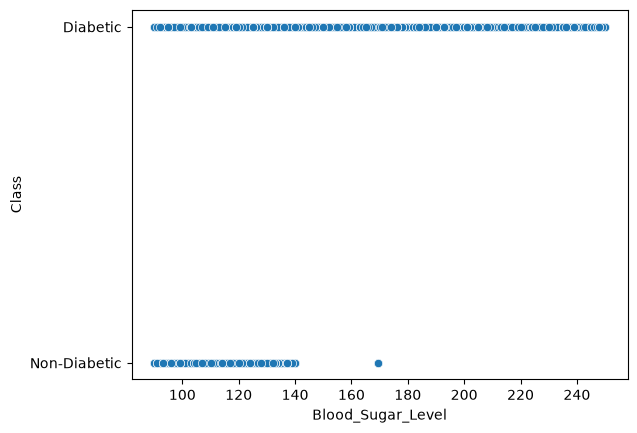

In [13]:
sns.scatterplot(data=df,x='Blood_Sugar_Level',y='Class')

In [14]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for col in['Class','Gender']:
    df[col]=le.fit_transform(df[col])

In [15]:
x=df.drop(['Class'],axis=1)
y=df['Class']

In [16]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=100,stratify=y)


In [17]:
print('x_train=',x_train.shape,'y_train=',y_train.shape)
print('x_test=',x_test.shape,'y_test=',y_test.shape)


x_train= (8000, 8) y_train= (8000,)
x_test= (2000, 8) y_test= (2000,)


In [18]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 8000 entries, 9946 to 1859
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                8000 non-null   float64
 1   Gender             8000 non-null   int64  
 2   Blood_Sugar_Level  8000 non-null   float64
 3   Creatinine         8000 non-null   float64
 4   BMI                8000 non-null   float64
 5   Urea               8000 non-null   float64
 6   Cholesterol        8000 non-null   float64
 7   HbA1c              8000 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 562.5 KB


In [19]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)


In [20]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [21]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,classification_report,balanced_accuracy_score,confusion_matrix

In [22]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1829
           1       0.83      0.83      0.83       171

    accuracy                           0.97      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.97      0.97      0.97      2000



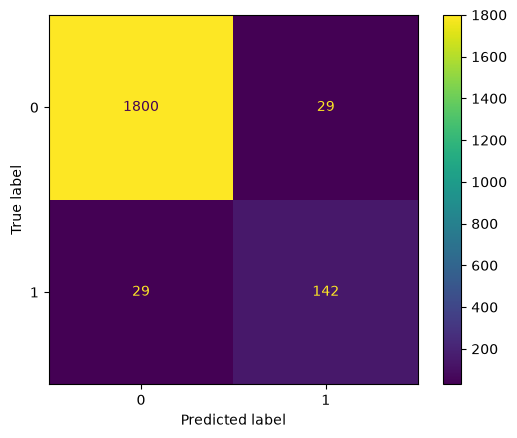

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm).plot()
plt.show()

In [24]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)

model_dt.fit(x_train, y_train)

y_pred_dt = model_dt.predict(x_test)

In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1829
           1       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [26]:
print("Training Accuracy:",
      model_dt.score(x_train, y_train))

print("Testing Accuracy:",
      model_dt.score(x_test, y_test))

Training Accuracy: 1.0
Testing Accuracy: 1.0


In [27]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model_dt,
    x_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Scores:", scores)
print("Mean Accuracy:", scores.mean())

Scores: [1.       1.       0.99875  1.       0.999375]
Mean Accuracy: 0.999625
